**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Luis Felipe García Domínguez

# Tarea: Métricas de Clasificación
## Dataset: Bank Marketing - UCI (Moro et al., 2014)

---

# 1. Preparación del entorno y librerías

Comenzamos importando las librerías necesarias para el análisis. Utilizaremos `numpy` y `pandas` para el manejo y estructuración de los datos, `matplotlib` y `seaborn` para la generación de gráficos, y `sklearn` para el modelado y evaluación de clasificadores.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", __import__("matplotlib").__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.3
pandas       3.0.6
matplotlib   3.11.2
scikit-learn 1.9.1


Configuramos la paleta de colores y algunos parámetros visuales. Asimismo, fijamos una semilla aleatoria (`SEMILLA = 42`) para garantizar la reproducibilidad de los resultados.

In [2]:
# Paleta de colores
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"
GRIS = "#5B6584"

# Configuración de Matplotlib
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

SEMILLA = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

---

# 2. Carga y exploración inicial de los datos

El conjunto de datos proviene del repositorio UCI Machine Learning y describe campañas de telemarketing telefónico realizadas por una institución bancaria de Portugal entre mayo de 2008 y noviembre de 2010 (Moro et al., 2014). El objetivo comercial del banco consistió en ofrecer depósitos a plazo fijo (*term deposits*) a sus clientes.

Utilizamos el archivo principal `bank-additional-full.csv`, el cual contiene `41,188 registros` con `20 variables predictoras` y la variable objetivo `y` (si el cliente aceptó o no la oferta).

In [3]:
from pathlib import Path

# Carga de datos
ruta_datos = Path("../data/bank-additional-full.csv")
if not ruta_datos.exists():
    ruta_datos = Path("homework/metricas/data/bank-additional-full.csv")

df = pd.read_csv(ruta_datos, sep=";")
print(f"Dimensiones del dataset: {df.shape[0]:,} filas y {df.shape[1]} columnas.")
df.head()

Dimensiones del dataset: 41,188 filas y 21 columnas.


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Inspeccionamos los tipos de variables presentes en el conjunto. Se cuenta con variables numéricas (características del cliente, historial de contacto e indicadores macroeconómicos) y variables categóricas (profesión, estado civil, nivel de estudios, entre otras).

Cabe resaltar que el archivo no contiene valores nulos estándar (`NaN`), sino que las categorías no informadas se encuentran codificadas bajo la etiqueta `unknown`.

In [4]:
# Clasificación de variables por tipo de dato
categoricas = df.select_dtypes(include=["object", "string"]).columns.drop("y").tolist()
numericas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print(f"Variables numéricas ({len(numericas)}):", numericas)
print(f"Variables categóricas ({len(categoricas)}):", categoricas)

# Conteo de valores 'unknown' por columna
valores_unknown = (df == "unknown").sum()
valores_unknown = valores_unknown[valores_unknown > 0]
if not valores_unknown.empty:
    print("\nValores 'unknown' por columna:")
    for col, cant in valores_unknown.items():
        print(f"  - {col}: {cant:,} registros ({cant / len(df):.2%})")

Variables numéricas (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Variables categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Valores 'unknown' por columna:
  - job: 330 registros (0.80%)
  - marital: 80 registros (0.19%)
  - education: 1,731 registros (4.20%)
  - default: 8,597 registros (20.87%)
  - housing: 990 registros (2.40%)
  - loan: 990 registros (2.40%)


Analizamos la distribución de la variable objetivo `y`, la cual registra la respuesta final del cliente frente a la propuesta del depósito bancario.

Distribución de la variable objetivo (y):
     Clientes Porcentaje
y                       
no      36548     88.73%
yes      4640     11.27%


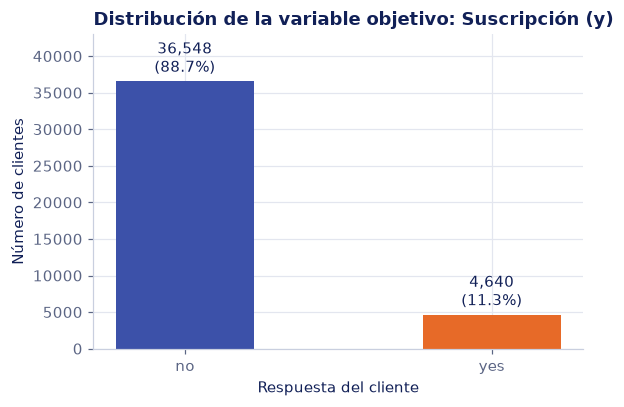

In [5]:
# Distribución de la variable objetivo
distribucion = df["y"].value_counts()
proporciones = df["y"].value_counts(normalize=True)

tabla_target = pd.DataFrame({
    "Clientes": distribucion,
    "Porcentaje": proporciones.map("{:.2%}".format)
})
print("Distribución de la variable objetivo (y):")
print(tabla_target)

# Gráfico de la variable objetivo
fig, ax = plt.subplots(figsize=(5.5, 3.8))
barras = ax.bar(distribucion.index, distribucion.values, color=[AZUL_MEDIO, NARANJA], width=0.45)

for barra in barras:
    yval = barra.get_height()
    pct = yval / len(df) * 100
    ax.text(barra.get_x() + barra.get_width() / 2, yval + 600,
            f"{yval:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, color=AZUL_OSCURO)

ax.set_title("Distribución de la variable objetivo: Suscripción (y)")
ax.set_xlabel("Respuesta del cliente")
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, 43000)
plt.tight_layout()
plt.show()

**Lectura.** El conjunto de datos reúne $41,188$ observaciones y $21$ atributos. La variable objetivo muestra un fuerte desbalance de clases: $36,548$ clientes ($88.73\%$) rechazaron la oferta ("no") y únicamente $4,640$ ($11.27\%$) la aceptaron ("yes"). Esto confirma que aproximadamente **1 de cada 9** clientes acepta el depósito a plazo, lo que implica que predecir siempre la clase mayoritaria otorgaría una exactitud engañosa de casi $89\%$, sin ser de utilidad para el banco.

---

## 2.1. Selección de variables

Al revisar la descripción del conjunto de datos en `bank-additional-names.txt`, la documentación nos da una advertencia sobre el atributo `duration`:

> *"11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model."*

Conforme a lo señalado en la documentación y considerando que este conjunto de datos recopila la información generada **después** de que concluyó la campaña telefónica. En el momento en que el banco debe decidir a qué clientes llamar, la llamada aún no ocurre; por lo tanto, la duración es imposible de conocer. Si se incluyera para entrenar el modelo, se provocaría una **fuga de información**. Por lo tanto, eliminaremos el atributo `duration` y transformaremos la variable objetivo `y`, cuyos valores son originalmente: `yes` y `no`, a una variable binaria donde `1 = yes`, y `0 = no`.

In [6]:
# Eliminación de duration
# Transformamos la variable objetivo 'y' a binaria
y = (df["y"] == "yes").astype(int)
X = df.drop(columns=["y", "duration"])

print(f"Dimensiones de la matriz de características X: {X.shape[0]:,} filas y {X.shape[1]} columnas.")
print(f"Variable eliminada: 'duration'")
print(f"Distribución de la variable objetivo y (binaria):")
print(f"  - Clase 0 (no aceptó): {(y == 0).sum():,} ({ (y == 0).mean():.2%})")
print(f"  - Clase 1 (aceptó):    {(y == 1).sum():,} ({ (y == 1).mean():.2%})")

Dimensiones de la matriz de características X: 41,188 filas y 19 columnas.
Variable eliminada: 'duration'
Distribución de la variable objetivo y (binaria):
  - Clase 0 (no aceptó): 36,548 (88.73%)
  - Clase 1 (aceptó):    4,640 (11.27%)


**Lectura.** La variable que el banco no podría conocer en el momento de decidir a quién llamar es `duration` (duración del último contacto en segundos). Incluirla introduce una fuga de información (*data leakage*), ya que una conversación prolongada es consecuencia del interés del cliente y no una característica observable previa a marcar. Aunque en investigación académica sirve como *benchmark* técnico para conocer el límite superior de rendimiento, para construir un modelo predictivo realista debe descartarse obligatoriamente.

---

# 3. Partición estratificada y clasificador base

Separamos el 20 % de los datos para prueba mediante una partición estratificada (`stratify=y`), lo que nos asegura que tanto el conjunto de entrenamiento como el de prueba mantengan la misma proporción exacta de clientes que aceptaron (11.27 %) y que rechazaron (88.73 %) el depósito.

Procedemos a evaluar el desempeño de un clasificador de referencia (línea base) que predice que ningún cliente aceptará la oferta, esto respondiendo siempre `no` (0).

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Partición estratificada 80/20
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)

print(f"Conjunto de entrenamiento: {len(y_entrena):,} clientes ({len(y_entrena)/len(y):.0%})")
print(f"  - Clase 0 (no): {(y_entrena == 0).sum():,} ({(y_entrena == 0).mean():.2%})")
print(f"  - Clase 1 (yes): {(y_entrena == 1).sum():,} ({(y_entrena == 1).mean():.2%})")

print(f"\nConjunto de prueba:        {len(y_prueba):,} clientes ({len(y_prueba)/len(y):.0%})")
print(f"  - Clase 0 (no): {(y_prueba == 0).sum():,} ({(y_prueba == 0).mean():.2%})")
print(f"  - Clase 1 (yes): {(y_prueba == 1).sum():,} ({(y_prueba == 1).mean():.2%})")

# Clasificador base: siempre responde 'no' (0)
pred_siempre_no = np.zeros(len(y_prueba), dtype=int)
exactitud_base = accuracy_score(y_prueba, pred_siempre_no)

print(f"\nExactitud del clasificador 'Linea Base': {exactitud_base:.4f} ({exactitud_base:.2%})")

Conjunto de entrenamiento: 32,950 clientes (80%)
  - Clase 0 (no): 29,238 (88.73%)
  - Clase 1 (yes): 3,712 (11.27%)

Conjunto de prueba:        8,238 clientes (20%)
  - Clase 0 (no): 7,310 (88.74%)
  - Clase 1 (yes): 928 (11.26%)

Exactitud del clasificador 'Linea Base': 0.8874 (88.74%)


**Lectura.** Observamos que un clasificador que siempre responde `no` obtiene una exactitud del $88.74\%$, un porcentaje alto si consideramos que se trata de un modelo trivial. Sin embargo, es fácil notar por qué la exactitud en este caso es una métrica engañosa: este resultado es consecuencia directa del desbalance de clases de nuestro dataset, donde más del $88\%$ de los clientes no aceptaron la oferta. Por supuesto, este clasificador base no es útil, ya que falla en detectar a los clientes interesados en contratar el depósito.

---

# 4. Regresión logística y métricas (umbral 0.5)

Construimos un `Pipeline` que integra el preprocesamiento y el clasificador:
1. **Preprocesamiento con `ColumnTransformer`:**
   - Variables numéricas: escaladas con `StandardScaler` para estandarizarlas a media 0 y varianza 1.
   - Variables categóricas: transformadas a variables indicadoras (*dummy*) mediante `OneHotEncoder(drop='first', handle_unknown='ignore')`.
2. **Modelo:** `LogisticRegression` ajustado con `max_iter=1000` y `random_state=42`.

Con lo anterior, aseguramos que los parámetros de escalado y las categorías se aprendan solo sobre el conjunto de entrenamiento (`X_entrena`). Implementamos el Pipeline primero identificando cuáles columnas son numéricas y cuáles son categóricas, posteriormente aplicamos el preprocesamiento según el tipo de columna (`punto 1`), y ajustamos el modelo (`punto 2`).

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Identificamos las columnas numéricas y categóricas en X
categoricas = X.select_dtypes(include=["object", "string"]).columns.tolist()
numericas = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Preprocesador por tipo de columna
preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), categoricas)
    ]
)

# Ensamblado del Pipeline
pipeline_logit = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=SEMILLA))
])

# Ajuste del modelo sobre los datos de entrenamiento
pipeline_logit.fit(X_entrena, y_entrena)

print("Pipeline ajustado exitosamente:")
print(pipeline_logit)

Pipeline ajustado exitosamente:
Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['job', 'marital',
                                                   'education', 'default',
                          

### Matriz de confusión (umbral 0.5)

Obtenemos la probabilidad estimada de éxito para cada cliente en prueba: $p = P(y = 1 \mid X)$. Con el umbral de $0.5$, clasificamos como positivo (1) a quien tenga $p \ge 0.5$, y como negativo (0) en caso contrario.

A partir de estas decisiones construimos la **matriz de confusión**, que desglosa los aciertos y errores del modelo:
- **Verdaderos Negativos (TN / VN):** Clientes que no contrataron y el modelo predijo correctamente que no contratarían.
- **Falsos Positivos (FP):** Clientes que no contrataron, pero el modelo predijo erróneamente que sí lo harían.
- **Falsos Negativos (FN):** Clientes que sí habrían contratado, pero el modelo los clasificó como no interesados.
- **Verdaderos Positivos (TP / VP):** Clientes que contrataron y el modelo identificó con éxito.

Matriz de confusión (umbral = 0.5):
[[VN=7218, FP=92]
 [FN=720, VP=208]]

Total evaluados: 8,238 clientes (Negativos reales: 7,310, Positivos reales: 928)


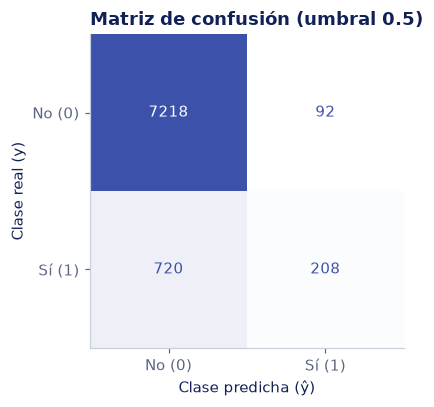

In [9]:
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Probabilidades estimadas para la clase positiva (y=1)
p_prueba = pipeline_logit.predict_proba(X_prueba)[:, 1]
pred_05 = (p_prueba >= 0.5).astype(int)

# Cálculo de la matriz de confusión
matriz_05 = confusion_matrix(y_prueba, pred_05)
vn, fp, fn, vp = matriz_05.ravel()

print("Matriz de confusión (umbral = 0.5):")
print(f"[[VN={vn}, FP={fp}]")
print(f" [FN={fn}, VP={vp}]]\n")
print(f"Total evaluados: {len(y_prueba):,} clientes (Negativos reales: {vn + fp:,}, Positivos reales: {fn + vp:,})")

# Visualización
azules = LinearSegmentedColormap.from_list("azules", ["#FFFFFF", AZUL_MEDIO])
fig, ax = plt.subplots(figsize=(4.6, 3.8))
disp = ConfusionMatrixDisplay(matriz_05, display_labels=["No (0)", "Sí (1)"])
disp.plot(ax=ax, cmap=azules, colorbar=False)

ax.grid(False)
ax.set_title("Matriz de confusión (umbral 0.5)")
ax.set_xlabel("Clase predicha (ŷ)")
ax.set_ylabel("Clase real (y)")
plt.tight_layout()
plt.show()

**Lectura.** Con un umbral $0.5$, observamos un modelo conservador ya que:

- Identifica correctamente a la gran mayoría de clientes que no tienen interés en el producto ($\text{VN} = 7,218$).
- Molesta a muy pocos clientes que terminan rechazando la oferta ($\text{FP} = 92$).
- Es bastante confiable cuando decide predecir que sí contratan ($\text{VP} = 208$).
- Deja escapar a la mayor parte de los clientes que sí habrían contratado el depósito ($\text{FN} = 720$).

Fijar un umbral de $0.5$ permite que al banco no realice tantas llamadas inútiles, a costa de ignorar a casi 8 de cada 10 clientes dispuestos a contratar.

### Fórmulas de evaluación

A partir de los cuatro cuadrantes de la matriz de confusión, calculamos distintas métricas utilizando las fórmulas vistas en clase:

- **Exactitud (Accuracy - ACC):** Proporción total de decisiones correctas.
  $$\text{ACC} = \frac{\text{TP} + \text{TN}}{\text{P} + \text{N}} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}} \tag{1}$$

- **Sensibilidad (Recall / True Positive Rate - TPR):** Capacidad del modelo para detectar a los clientes que realmente contratan.
  $$\text{TPR} = \frac{\text{TP}}{\text{P}} = \frac{\text{TP}}{\text{TP} + \text{FN}} \tag{2}$$

- **Especificidad (True Negative Rate - TNR):** Capacidad del modelo para descartar a los clientes que no van a contratar.
  $$\text{TNR} = \frac{\text{TN}}{\text{N}} = \frac{\text{TN}}{\text{TN} + \text{FP}} \tag{3}$$

- **Precisión (Positive Predictive Value - PPV):** De todos los clientes a los que el modelo decide llamar, qué porcentaje realmente contrata el depósito.
  $$\text{PPV} = \frac{\text{TP}}{\text{TP} + \text{FP}} \tag{4}$$

- **Puntaje $F_1$ ($F_1$-score):** Media armónica balanceada entre precisión y sensibilidad.
  $$F_1 = 2 \cdot \frac{\text{PPV} \cdot \text{TPR}}{\text{PPV} + \text{TPR}} = \frac{2\text{TP}}{2\text{TP} + \text{FP} + \text{FN}} \tag{5}$$

Calculamos cada métrica de forma manual y las comparamos con las funciones nativas de scikit-learn. Cabe mencionar que scikit-learn no cuenta con una función directa para la `especificidad`. No obstante, como se vio en el notebook de clase, la especificidad es equivalente en concepto a la sensibilidad de la clase negativa (0), lo que permite verificarla en scikit-learn calculando el recall con `pos_label=0`, en lugar de `pos_label=1`.

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Métricas a partir de las fórmulas
acc_mano = (vp + vn) / (vp + vn + fp + fn)
rec_mano = vp / (vp + fn)      # Sensibilidad (TPR)
spec_mano = vn / (vn + fp)     # Especificidad (TNR)
prec_mano = vp / (vp + fp)     # Precisión (PPV)
f1_mano = 2 * (prec_mano * rec_mano) / (prec_mano + rec_mano)

# 2. Verificación con scikit-learn
acc_skl = accuracy_score(y_prueba, pred_05)
rec_skl = recall_score(y_prueba, pred_05)
spec_skl = recall_score(y_prueba, pred_05, pos_label=0)  # Especificidad = recall de la clase 0
prec_skl = precision_score(y_prueba, pred_05)
f1_skl = f1_score(y_prueba, pred_05)

# Comparativa de resultados
tabla_metricas = pd.DataFrame({
    "Fórmula (a mano)": [acc_mano, prec_mano, rec_mano, spec_mano, f1_mano],
    "scikit-learn": [acc_skl, prec_skl, rec_skl, spec_skl, f1_skl]
}, index=[
    "Exactitud (ACC)",
    "Precisión (PPV)",
    "Sensibilidad (TPR)",
    "Especificidad (TNR)",
    "F1-score (F1)"
]).round(4)

print("Comparación de métricas de desempeño (umbral = 0.5):")
print(tabla_metricas)

Comparación de métricas de desempeño (umbral = 0.5):
                     Fórmula (a mano)  scikit-learn
Exactitud (ACC)                0.9014        0.9014
Precisión (PPV)                0.6933        0.6933
Sensibilidad (TPR)             0.2241        0.2241
Especificidad (TNR)            0.9874        0.9874
F1-score (F1)                  0.3388        0.3388


**Lectura.** Con el umbral de $0.5$, el modelo alcanza $90.14\%$ de exactitud y $98.74\%$ de especificidad, pero su sensibilidad es de apenas $22.41\%$ (solo detecta **208 de los 928** clientes que aceptarían), con una precisión de $69.33\%$ y un F1 de $33.88\%$.

Respondiento la pregunta: *¿Cuál de esas métricas le importa más al banco, y por qué?*

Al banco le importaría principalmente la **precisión** ya que un call center no opera con recursos ilimitados y cada llamada sin éxito involucra un costo (tiempo y dinero), pues se requiere que la mayoría de las llamadas terminen en venta.  Dicho otro modo, una baja precisión implica *desperdiciar llamadas* por falsos positivos. 

Por otra parte, si el objetivo es maximizar la captación o si el margen de ganancia supera el costo de las llamadas, la **sensibilidad** tendría mayor relevancia para reducir los falsos negativos y no dejar escapar clientes dispuestos a contratar. Es decir, una baja sensibilidad implica *perder clientes* por no llamarlos.

---

# 5. Curva ROC y Curva de Precisión contra Sensibilidad

Hasta el momento evaluamos el modelo fijando un único umbral ($t = 0.5$). Sin embargo, variar el umbral de decisión permite recorrer todos los balances posibles entre sensibilidad y falsos positivos.

Para esto, utilizamos dos curvas:
1. **Curva ROC (Receiver Operating Characteristic):** Grafica la sensibilidad (tasa de verdaderos positivos, TPR) contra la tasa de falsos positivos (FPR = $1 - \text{Especificidad}$). Su métrica resumen es el **AUC-ROC** (Área Bajo la Curva), que mide la probabilidad de que un cliente que sí contrató reciba una probabilidad estimada mayor que uno que no contrató.
2. **Curva de Precisión contra Sensibilidad (PR - Precision-Recall):** Grafica la precisión (PPV) frente a la sensibilidad (TPR) para cada umbral. Su métrica resumen es la **Precisión Promedio (Average Precision - AP)**, equivalente al área bajo la curva PR.

Área bajo la curva ROC (AUC-ROC): 0.8007
Precisión promedio (Average Precision - AP): 0.4657
Línea base de precisión (proporción de positivos): 0.1126 (11.26%)


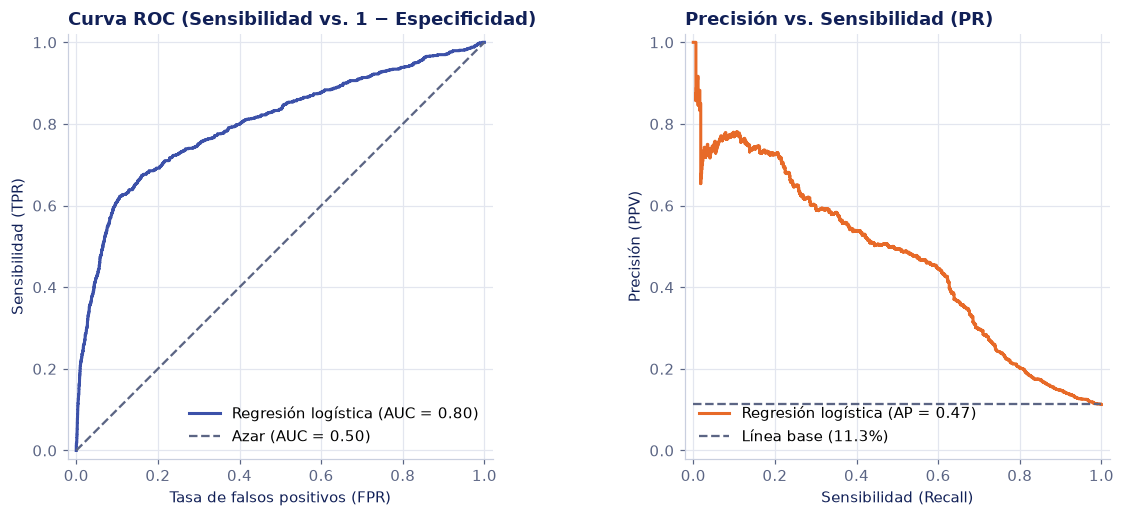

In [11]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score, average_precision_score

# Cálculo de AUC-ROC y Precisión Promedio (AP)
auc_roc = roc_auc_score(y_prueba, p_prueba)
ap_score = average_precision_score(y_prueba, p_prueba)

print(f"Área bajo la curva ROC (AUC-ROC): {auc_roc:.4f}")
print(f"Precisión promedio (Average Precision - AP): {ap_score:.4f}")
print(f"Línea base de precisión (proporción de positivos): {y_prueba.mean():.4f} ({y_prueba.mean():.2%})")

# Gráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8))

# Panel 1: Curva ROC
RocCurveDisplay.from_estimator(
    pipeline_logit,
    X_prueba,
    y_prueba,
    ax=ax1,
    name="Regresión logística",
    curve_kwargs={"color": AZUL_MEDIO, "linewidth": 2},
    plot_chance_level=True,
    chance_level_kw={"color": GRIS, "linestyle": "--", "label": "Azar (AUC = 0.50)"}
)
ax1.set_title("Curva ROC (Sensibilidad vs. 1 − Especificidad)")
ax1.set_xlabel("Tasa de falsos positivos (FPR)")
ax1.set_ylabel("Sensibilidad (TPR)")
ax1.set_xlim(-0.02, 1.02)
ax1.set_ylim(-0.02, 1.02)
ax1.set_aspect("equal", adjustable="box")

# Panel 2: Curva de Precisión vs. Sensibilidad
PrecisionRecallDisplay.from_estimator(
    pipeline_logit,
    X_prueba,
    y_prueba,
    ax=ax2,
    name="Regresión logística",
    curve_kwargs={"color": NARANJA, "linewidth": 2},
    plot_chance_level=True,
    chance_level_kw={"color": GRIS, "linestyle": "--", "label": f"Línea base ({y_prueba.mean():.1%})"}
)
ax2.set_title("Precisión vs. Sensibilidad (PR)")
ax2.set_xlabel("Sensibilidad (Recall)")
ax2.set_ylabel("Precisión (PPV)")
ax2.set_xlim(-0.02, 1.02)
ax2.set_ylim(-0.02, 1.02)
ax2.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

**Lectura.** La curva ROC alcanza un AUC de $0.8007$, mientras que la curva de Precisión contra Sensibilidad obtiene una precisión promedio (AP) de $0.4657$.

Un recurso útil para interpretar estos resultados es observar a qué pregunta responde exactamente cada curva.
- **La curva ROC nos dice:** *de todos los clientes que no querían el depósito, ¿a qué fracción molestamos por error vs. qué fracción de los que sí querían logramos capturar?*

    - Si el AUC fuera $0.50$ (azar): para capturar al $80\%$ de los que sí quieren, habría que molestar (forzosamente) al $80\%$ de los que no quieren.
    - Con el $0.80$: logramos capturar a una alta proporción de interesados molestando a una fracción mucho menor de clientes *negativos*.


Sin embargo, esta curva esconde el impacto de las falsas alarmas porque su eje horizontal divide los falsos positivos entre el total de negativos reales ($\text{FPR} = \frac{\text{FP}}{\text{VN} + \text{FP}}$); al haber tantos clientes que rechazan el depósito (7,310 negativos en prueba), el denominador es muy grande y mantiene la tasa de falsos positivos artificialmente baja, dando una ilusión optimista del modelo.

Por otra parte:

- **La curva Precisión-Sensibilidad nos dice:** *de las llamadas que hacemos, ¿qué fracción resultará en éxito vs. qué fracción del total de interesados logramos abarcar?*

    - Si el banco llamara al azar o a toda su base, solo el $11.3\%$ de las llamadas tendrían éxito (esto es, la linea base).
    - Si el banco utiliza el modelo, que logra una precisión promedio de $46.6\%$, multiplica por 4 la efectividad promedio de cada llamada realizada.

En contraste, esta curva no toma en cuenta los verdaderos negativos y enfrenta directamente los aciertos contra las falsas alarmas ($\text{PPV} = \frac{\text{VP}}{\text{VP} + \text{FP}}$), mostrando la realidad: a medida que el banco intenta incrementar la sensibilidad para capturar más clientes, la precisión cae debido a que se acumulan más llamadas fallidas.

---

# 6. Umbral de Decisión Económica

Buscamos determinar a partir de qué probabilidad conviene llamar. Para esto, consideramos los parámetros del problema:

- Costo operativo por llamada: $C = \$5$
- Ganancia neta por cliente que contrata: $G = \$50$

Y definimos $p^*$ como el umbral óptimo.

Si el modelo estima que un cliente tiene una probabilidad $p$ de contratar el depósito, el **retorno esperado** de realizar esa llamada es:

$$
\mathbb{E}[\text{Ganancia}] = p \cdot (G - C) + (1 - p) \cdot (-C) = p \cdot G - C = 50p - 5
$$

Para que al banco le convenga realizar la llamada, el retorno esperado debe ser mayor a cero. Resolvemos la desigualdad:

$$
\begin{aligned}
50p - 5 &> 0 \\
50p &> 5 \\
p &> \frac{5}{50} = 0.10
\end{aligned}
$$

Por lo tanto, el **umbral mínimo** es $p^* = 0.10$ ($10\,\%$). Cualquier cliente con una probabilidad estimada que supere el $10\,\%$ aporta un balance positivo al banco, aun sabiendo que alrededor del $90\,\%$ de ellos no contratará.

Para contrastar el umbral base con el umbral óptimo definimos algunas métricas.

Sean $c$ el `costo unitario` y $g$ la `ganancia neta`:

$$
\begin{aligned}
N_{\text{llamadas}} &= \text{VP} + \text{FP} \\
C &= c \cdot N_{\text{llamadas}} \\
I &= g \cdot \text{VP} \\
G_{\text{neta}} &= I - C = g \cdot \text{VP} - c (\text{VP} + \text{FP}) \\
P &= \frac{\text{VP}}{\text{VP} + \text{FP}} \quad (\text{para } \text{VP} + \text{FP} > 0) \\
R &= \frac{\text{VP}}{\text{VP} + \text{FN}}
\end{aligned}
$$

Formalizamos las métricas de negocio con las variables del modelo ($c = \text{costo}$, $g = \text{ganancia}$, $C = \text{costos}$, $I = \text{ingresos}$ y $G_{\text{neta}} = \text{ganancia\_neta}$):

In [12]:
# Evaluación del impacto financiero de cualquier umbral
costo_llamada = 5
ganancia_exito = 50

def evaluar_umbral_economico(y_real, probabilidades, umbral, costo=5, ganancia=50):
    pred = (probabilidades >= umbral).astype(int)
    vp = int(np.sum((y_real == 1) & (pred == 1)))
    fp = int(np.sum((y_real == 0) & (pred == 1)))
    fn = int(np.sum((y_real == 1) & (pred == 0)))
    vn = int(np.sum((y_real == 0) & (pred == 0)))
    
    llamadas = vp + fp
    costos = llamadas * costo
    ingresos = vp * ganancia
    ganancia_neta = ingresos - costos
    precision = vp / llamadas if llamadas > 0 else 0
    recall = vp / (vp + fn)
    
    return {
        "Umbral": umbral,
        "Llamadas": llamadas,
        "Éxitos (VP)": vp,
        "Falsas alarmas (FP)": fp,
        "Precisión": precision,
        "Sensibilidad": recall,
        "Costos ($)": costos,
        "Ingresos ($)": ingresos,
        "Ganancia neta ($)": ganancia_neta,
    }

# Comparación entre umbral base (0.50) y umbral económico (0.10)
df_comparacion = pd.DataFrame([
    evaluar_umbral_economico(y_prueba, p_prueba, umbral=0.50),
    evaluar_umbral_economico(y_prueba, p_prueba, umbral=0.10),
])

df_comparacion.style.format({
    "Precisión": "{:.2%}",
    "Sensibilidad": "{:.2%}",
    "Costos ($)": "${:,.0f}",
    "Ingresos ($)": "${:,.0f}",
    "Ganancia neta ($)": "${:,.0f}",
})

,Umbral,Llamadas,Éxitos (VP),Falsas alarmas (FP),Precisión,Sensibilidad,Costos ($),Ingresos ($),Ganancia neta ($)
0,0.500000,300,208,92,69.33%,22.41%,"$1,500","$10,400","$8,900"
1,0.100000,1898,631,1267,33.25%,68.00%,"$9,490","$31,550","$22,060"


**Lectura.** Aunque reducir el umbral de $0.50$ a $0.10$ disminuye la precisión de $69.3\,\%$ a $33.2\,\%$, permite capturar al $68.0\,\%$ de los clientes interesados (631 conversiones frente a solo 208), demostrando que fijar $0.50$ afectaba el valor del negocio al reducirlo a más de la mitad.

Observemos esto graficamente.

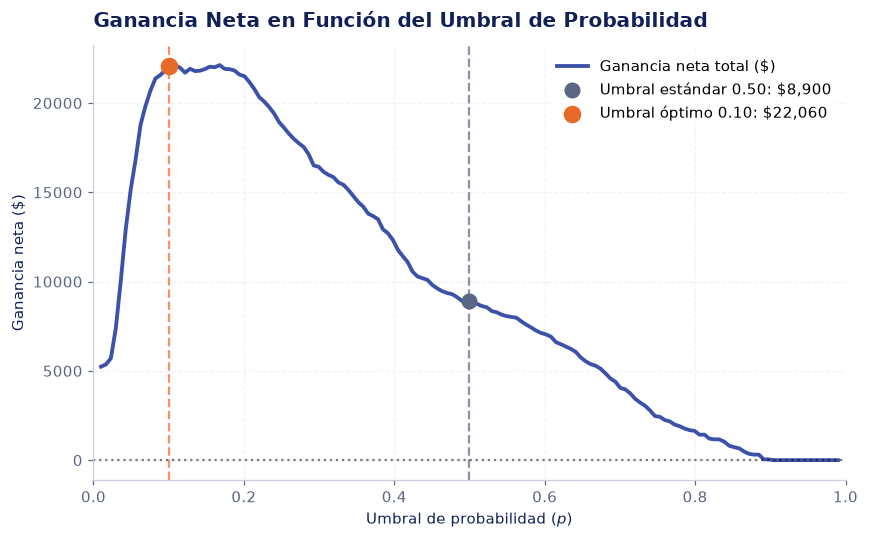

In [13]:
# Curva de ganancia neta en función del umbral de probabilidad
umbrales = np.linspace(0.01, 0.99, 150)
ganancias = [evaluar_umbral_economico(y_prueba, p_prueba, t)["Ganancia neta ($)"] for t in umbrales]

g_05 = evaluar_umbral_economico(y_prueba, p_prueba, 0.50)["Ganancia neta ($)"]
g_01 = evaluar_umbral_economico(y_prueba, p_prueba, 0.10)["Ganancia neta ($)"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(umbrales, ganancias, color=AZUL_MEDIO, lw=2.5, label="Ganancia neta total ($)")

# Puntos de interés
ax.scatter([0.50], [g_05], color=GRIS, s=90, zorder=5, label=f"Umbral estándar 0.50: ${g_05:,.0f}")
ax.scatter([0.10], [g_01], color=NARANJA, s=110, zorder=5, label=f"Umbral óptimo 0.10: ${g_01:,.0f}")

ax.axvline(0.10, color=NARANJA, linestyle="--", alpha=0.7)
ax.axvline(0.50, color=GRIS, linestyle="--", alpha=0.7)
ax.axhline(0, color="black", linestyle=":", alpha=0.5)

ax.set_title("Ganancia Neta en Función del Umbral de Probabilidad", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Umbral de probabilidad ($p$)")
ax.set_ylabel("Ganancia neta ($)")
ax.set_xlim(0, 1)
ax.legend(frameon=True, facecolor="white", edgecolor="none")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Lectura.** El umbral mínimo para el cual conviene llamar es $p^* = \frac{5}{50} = 0.10$, obtenido al plantear que la ganancia esperada por llamada supere el costo operativo.

Al comparar ambos umbrales en el conjunto de prueba, el umbral óptimo de $0.10$ genera una ganancia neta de $\$22,060$ frente a apenas $\$8,900$ con el umbral estándar de $0.50$, lo que representa un incremento del $+147.9\,\%$ (o $\$13,160$ adicionales).

---

# 7. Reentrenamiento del Modelo con la Variable Omitida (`duration`)

En la sección 2.1 eliminamos la variable `duration` para evitar fuga de información. En esta sección volvemos a entrenar la regresión logística bajo las mismas condiciones, pero incorporando `duration` como categoría predictora para comparar el comportamiento de las métricas.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Datos completos conservando duration
X_dur = df.drop(columns=["y"])
y_dur = (df["y"] == "yes").astype(int)

X_entrena_dur, X_prueba_dur, y_entrena_dur, y_prueba_dur = train_test_split(
    X_dur, y_dur, test_size=0.20, stratify=y_dur, random_state=SEMILLA
)

# Definir variables numéricas (incluyendo duration) y categóricas
vars_num_dur = X_dur.select_dtypes(include=[np.number]).columns.tolist()
vars_cat_dur = X_dur.select_dtypes(include=["object"]).columns.tolist()

preprocesador_dur = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), vars_num_dur),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), vars_cat_dur),
    ]
)

pipeline_dur = Pipeline([
    ("preprocesador", preprocesador_dur),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=SEMILLA)),
])

pipeline_dur.fit(X_entrena_dur, y_entrena_dur)

# Predicciones con umbral 0.5
y_pred_dur = pipeline_dur.predict(X_prueba_dur)
cm_dur = confusion_matrix(y_prueba_dur, y_pred_dur)

# Métricas comparativas
metricas_comparadas = pd.DataFrame({
    "Métrica": ["Exactitud", "Precisión", "Sensibilidad", "Especificidad", "F1-Score"],
    "Sin duration (Modelo Real)": [
        accuracy_score(y_prueba, (p_prueba >= 0.5).astype(int)),
        precision_score(y_prueba, (p_prueba >= 0.5).astype(int)),
        recall_score(y_prueba, (p_prueba >= 0.5).astype(int)),
        recall_score(y_prueba, (p_prueba >= 0.5).astype(int), pos_label=0),
        f1_score(y_prueba, (p_prueba >= 0.5).astype(int)),
    ],
    "Con duration (Modelo con Fuga)": [
        accuracy_score(y_prueba_dur, y_pred_dur),
        precision_score(y_prueba_dur, y_pred_dur),
        recall_score(y_prueba_dur, y_pred_dur),
        recall_score(y_prueba_dur, y_pred_dur, pos_label=0),
        f1_score(y_prueba_dur, y_pred_dur),
    ],
})

metricas_comparadas["Diferencia (pp)"] = (
    metricas_comparadas["Con duration (Modelo con Fuga)"] - metricas_comparadas["Sin duration (Modelo Real)"]
) * 100

metricas_comparadas.style.format({
    "Sin duration (Modelo Real)": "{:.2%}",
    "Con duration (Modelo con Fuga)": "{:.2%}",
    "Diferencia (pp)": "{:+.2f} pp",
})

,Métrica,Sin duration (Modelo Real),Con duration (Modelo con Fuga),Diferencia (pp)
0,Exactitud,90.14%,91.62%,+1.48 pp
1,Precisión,69.33%,70.95%,+1.62 pp
2,Sensibilidad,22.41%,43.43%,+21.01 pp
3,Especificidad,98.74%,97.74%,-1.00 pp
4,F1-Score,33.88%,53.88%,+20.00 pp


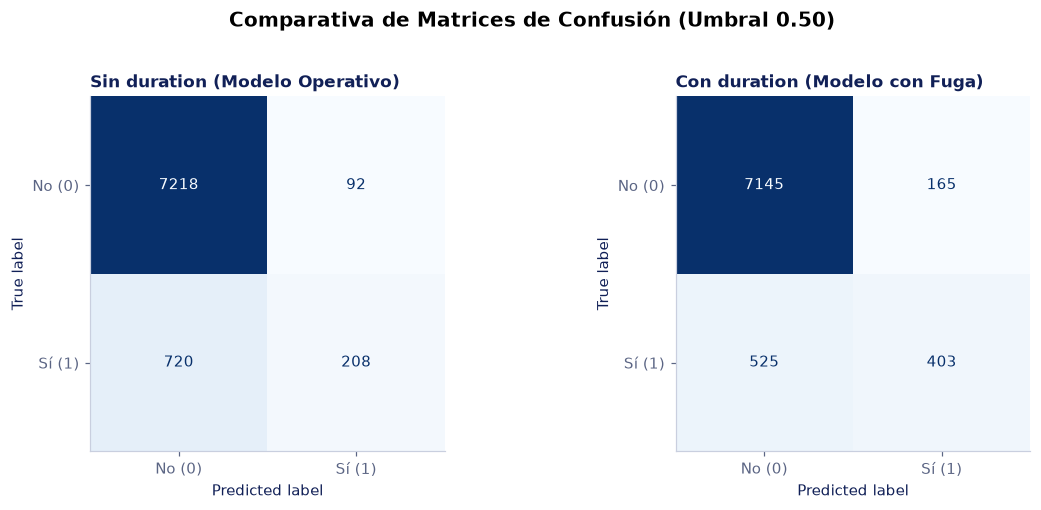

In [15]:
# Comparación de matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

disp_real = ConfusionMatrixDisplay(matriz_05, display_labels=["No (0)", "Sí (1)"])
disp_real.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Sin duration (Modelo Operativo)", fontsize=11, fontweight="bold")
axes[0].grid(False)

disp_dur = ConfusionMatrixDisplay(cm_dur, display_labels=["No (0)", "Sí (1)"])
disp_dur.plot(ax=axes[1], cmap="Blues", values_format="d", colorbar=False)
axes[1].set_title("Con duration (Modelo con Fuga)", fontsize=11, fontweight="bold")
axes[1].grid(False)

plt.suptitle("Comparativa de Matrices de Confusión (Umbral 0.50)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Lectura.** Al incluir `duration`, la sensibilidad casi se duplica de $22.41\,\%$ a $43.43\,\%$ y el $F_1$-score aumenta en $20.00$ puntos porcentuales (de $0.3388$ a $0.5388$). Sin embargo, este modelo "superior" no le sirve al banco porque en el momento de tomar la decisión de a quién llamar, la duración de la llamada es desconocida ($0$ segundos).

La duración es en realidad una consecuencia del interés del cliente y no una causa; si el banco intentara usar este modelo antes de llamar, tendría que inventar una duración o ingresar cero (lo que predeciría "no"), convirtiendo a este modelo en una herramienta inútil.

---

# 8. Conclusiones

Medir el éxito del modelo solo por los aciertos totales (`exactitud`) es engañoso: predecir siempre `no` daría casi un 89% de precisión, pero sin aportar conversión real. Lo que necesita el banco es encontrar el equilibrio entre capturar a la mayor cantidad de interesados posible y no hacer perder el tiempo a los asesores con llamadas inútiles (`sensibilidad` vs. `precisión`).

Por lo anterior, no tiene sentido esperar a que un cliente tenga un 50% de probabilidad para llamarlo. Como ganar un cliente deja una ganancia de $50 y la llamada solo cuesta $5, llamar a cualquiera con más de un 10% de interés ya es rentable.

---
### Declaración sobre el uso de IA Generativa

Este notebook fue laborado con apoyo de modelos de lenguaje basados en IA (Gemini / Antigravity) como herramientas de apoyo para la depuración de código, revisión de textos y formato markdown. El razonamiento analítico, el planteamiento metodológico, la interpretación de resultados y la redacción final de los hallazgos son responsabilidad del autor.